## 1. Project Overview & Objectives

Analyze ESA WorldCover 2021 v200 land cover at native resolution. See the [ESA product manual, sections 3-4](https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/docs/WorldCover_PUM_V2.0.pdf) and [dataset DOI](https://doi.org/10.5281/zenodo.7254221).

In [1]:
import csv
import hashlib
import json
import math
import re
import zlib
from pathlib import Path
from xml.etree import ElementTree as ET

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import numpy as np
from PIL import Image
from IPython.display import display, Markdown, Image as NotebookImage

def normalize(name):
    return re.sub(r"[^a-z0-9]", "", name.casefold())

for root in (Path.cwd(), *Path.cwd().parents):
    folders = [p for p in root.iterdir() if p.is_dir() and normalize(p.name) == "newdata"]
    if folders:
        break
if len(folders) != 1:
    raise ValueError("Run from the NASA project with one New Data folder.")
source, = folders
output = root / "ESA_WorldCover_Processed"
reports, figures, processed, metadata = (output / d for d in ("reports", "figures", "processed", "metadata"))
for folder in (reports, figures, processed, metadata):
    folder.mkdir(parents=True, exist_ok=True)
manual = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/docs/WorldCover_PUM_V2.0.pdf"
doi = "https://doi.org/10.5281/zenodo.7254221"
print(f"Inputs located in {source.relative_to(root)}. Outputs go to {output.name}.")

Inputs located in new_data. Outputs go to ESA_WorldCover_Processed.


## 2. Dataset Inspection

Read each TIFF header once and record a checksum. Pillow is used for the header only. The scan uses native compressed blocks.

In [2]:
def checksum(path):
    with path.open("rb") as f:
        return hashlib.file_digest(f, "sha256").hexdigest()

paths = sorted(p for p in source.rglob("*") if p.is_file() and p.suffix.lower() in (".tif", ".tiff"))
if not paths:
    raise FileNotFoundError(f"No TIFF files in {source}")
tiles = {}
inspected = {}
limit = Image.MAX_IMAGE_PIXELS
try:
    Image.MAX_IMAGE_PIXELS = 36000**2
    for path in paths:
        with Image.open(path) as image:
            tag = image.tag_v2
            xml = ET.fromstring(tag.get(42112, "<GDALMetadata/>"))
            attributes = {item.attrib["name"]: item.text for item in xml.findall("Item")}
            key_dir = tag.get(34735, ())
            keys = {key_dir[i]: key_dir[i+3] for i in range(4, len(key_dir), 4)
                    if key_dir[i+1:i+3] == (0, 1)}
            info = dict(
                path=path.relative_to(root).as_posix(), bytes=path.stat().st_size, sha256=checksum(path),
                width=image.width, height=image.height, bands=tag.get(277, 1),
                bits=tag.get(258), sample_format=tag.get(339, (1,)), compression=tag.get(259),
                predictor=tag.get(317, 1), planar_config=tag.get(284, 1), orientation=tag.get(274, 1),
                photometric=tag.get(262), extra_samples=tag.get(338), nodata_tag=tag.get(42113),
                geokeys=keys, pixel_scale=tag.get(33550), tiepoint=tag.get(33922),
                has_transform_matrix=34264 in tag, block_shape=[tag.get(323), tag.get(322)],
                overview_count=image.n_frames-1, attributes=attributes,
                offsets=tag.get(324), lengths=tag.get(325),
            )
            inspected[path] = info
        print(f"{path.name}: {info['width']:,} x {info['height']:,}, "
              f"{info['bands']} band(s), {info['bits']}, {info['bytes']:,} bytes")
finally:
    Image.MAX_IMAGE_PIXELS = limit

ESA_WorldCover_10m_2021_v200_N27W015_Map.tif: 36,000 x 36,000, 1 band(s), (8,), 5,583,741 bytes
ESA_WorldCover_10m_2021_v200_N36W117_Map.tif: 36,000 x 36,000, 1 band(s), (8,), 114,433,385 bytes
ESA_WorldCover_10m_2021_v200_S24W069_Map.tif: 36,000 x 36,000, 1 band(s), (8,), 57,288,645 bytes


## 3. Metadata & Data Validation

The official manual describes 3-degree WGS 84 tiles with one byte per map pixel and a nominal 10 m resolution. The observed spacing is 1/12000 degree. The value 1/1200 printed in section 3.4.1 conflicts with the TIFF grid and nominal resolution. Use the embedded georeferencing. NoData comes from the TIFF tag.

In [3]:
for path, info in inspected.items():
    attr, keys = info["attributes"], info["geokeys"]
    if attr.get("product_type") != "LandCover Map":
        if path.name.lower().endswith(("_map.tif", "_map.tiff")):
            raise ValueError(f"Unverified Map product: {path.name}")
        print(f"Header inspected outside Map layer: {path.name}")
        continue
    tile = attr["product_tile"]
    if tile in tiles:
        raise ValueError(f"Duplicate tile ID: {tile}")
    checks = {
        "product": attr.get("product_version") == "V2.0.0" and
                   all((attr.get(k) or "").startswith("2021-") for k in ("time_start", "time_end")),
        "dimensions": (info["width"], info["height"]) == (36000, 36000),
        "dtype": (info["bands"], info["bits"], info["sample_format"]) == (1, (8,), (1,)),
        "grid": keys.get(1024) == 2 and keys.get(2048) == 4326 and keys.get(1025) == 1
                and keys.get(2054) == 9102 and not info["has_transform_matrix"]
                and info["tiepoint"] is not None and len(info["tiepoint"]) == 6
                and info["pixel_scale"] is not None
                and np.allclose(info["pixel_scale"][:2], 1/12000, rtol=0, atol=1e-12),
        "block_format": info["compression"] in (8, 32946) and info["predictor"] == 1
                        and info["block_shape"] == [1024, 1024] and info["planar_config"] == 1
                        and info["orientation"] == 1 and info["photometric"] == 3
                        and not info["extra_samples"] and bool(info["offsets"]) and bool(info["lengths"]),
        "nodata": str(info["nodata_tag"]).strip() == "0",
    }
    if not all(checks.values()):
        raise ValueError(f"{path.name}: review product validation {checks}")
    ns, lat, ew, lon = re.fullmatch(r"([NS])(\d{2})([EW])(\d{3})", tile).groups()
    south_expected = int(lat) * (-1 if ns == "S" else 1)
    west_expected = int(lon) * (-1 if ew == "W" else 1)
    dx, dy = info["pixel_scale"][:2]
    i, j, _, x, y, _ = info["tiepoint"]
    west, north = x-i*dx, y+j*dy
    bounds = [west, north-info["height"]*dy, west+info["width"]*dx, north]
    if not np.allclose(bounds, [west_expected, south_expected, west_expected+3, south_expected+3],
                       atol=1e-10, rtol=0):
        raise ValueError(f"{tile}: embedded coordinates disagree with product tile ID.")
    info.update(crs="EPSG:4326", dtype="uint8", resolution_deg=[dx, dy], bounds_wsen=bounds,
                affine=[dx, 0, west, 0, -dy, north], nodata=0,
                registration="PixelIsArea", validation=checks)
    tiles[tile] = info
    print(f"{tile}: W/S/E/N {bounds}; {info['crs']}; {dx*3600:.1f} arcsec; NoData = 0")
if not tiles:
    raise ValueError("No validated WorldCover Map files.")

N27W015: W/S/E/N [-15.0, 27.0, -12.0, 30.0]; EPSG:4326; 0.3 arcsec; NoData = 0
N36W117: W/S/E/N [-117.0, 36.0, -114.0, 39.0]; EPSG:4326; 0.3 arcsec; NoData = 0
S24W069: W/S/E/N [-69.0, -24.0, -66.0, -21.0]; EPSG:4326; 0.3 arcsec; NoData = 0


## 4. Land Cover Classification

These are discrete ESA classes. Analytical groups summarize the original classes without changing their codes. The vegetation group includes cropland, vegetated wetlands and moss/lichen. Sparse vegetation stays with class 60.

In [4]:
classes = {
    10: ("Tree cover", "#006400"), 20: ("Shrubland", "#ffbb22"), 30: ("Grassland", "#ffff4c"),
    40: ("Cropland", "#f096ff"), 50: ("Built-up", "#fa0000"), 60: ("Bare / sparse vegetation", "#b4b4b4"),
    70: ("Snow and ice", "#f0f0f0"), 80: ("Permanent water bodies", "#0064c8"),
    90: ("Herbaceous wetland", "#0096a0"), 95: ("Mangroves", "#00cf75"), 100: ("Moss and lichen", "#fae6a0"),
}
groups = {"Water": [80], "Vegetation": [10, 20, 30, 40, 90, 95, 100],
          "Bare / sparse": [60], "Other": [50, 70]}
codes = list(classes)
assert sorted(code for members in groups.values() for code in members) == codes
for tile, info in tiles.items():
    embedded = dict(line.split(maxsplit=1) for line in info["attributes"]["legend"].splitlines() if line.strip())
    assert {int(k): normalize(v) for k, v in embedded.items()} == {
        k: normalize(v[0]) for k, v in classes.items()}, tile
print("\n".join(f"{code:>3}  {label}" for code, (label, _) in classes.items()))
print("Code 0 is NoData. Analytical groups:", groups)

 10  Tree cover
 20  Shrubland
 30  Grassland
 40  Cropland
 50  Built-up
 60  Bare / sparse vegetation
 70  Snow and ice
 80  Permanent water bodies
 90  Herbaceous wetland
 95  Mangroves
100  Moss and lichen
Code 0 is NoData. Analytical groups: {'Water': [80], 'Vegetation': [10, 20, 30, 40, 90, 95, 100], 'Bare / sparse': [60], 'Other': [50, 70]}


## 5. Data Quality Assessment

Count all native pixels in TIFF blocks and cache each completed tile. Count WorldCover coverage inside each NASADEM footprint during the same scan.

In [5]:
dem_path = root / "NASA_Processed/metadata/dataset_metadata.json"
dem = json.loads(dem_path.read_text(encoding="utf-8"))["geometry"] if dem_path.is_file() else {}
pairs = []
for tile, info in tiles.items():
    w,s,e,n = info["bounds_wsen"]
    dx,dy = info["resolution_deg"]
    for name, geo in dem.items():
        dw,ds,de,dn = geo["post_bounds_wsen"]
        pair = dict(tile=tile, nasadem_tile=name, status="No area overlap")
        if geo["horizontal_crs"] != info["crs"]:
            pair["status"] = "CRS differs"
        else:
            iw,ls,ie,un = max(w,dw),max(s,ds),min(e,de),min(n,dn)
            if iw < ie and ls < un:
                fraction = (ie-iw)*(un-ls)/((de-dw)*(dn-ds))
                edges = [(n-un)/dy,(n-ls)/dy,(iw-w)/dx,(ie-w)/dx]
                pair.update(status="Full DEM footprint" if math.isclose(fraction,1) else "Partial DEM footprint",
                            intersection_bounds_wsen=[iw,ls,ie,un], dem_footprint_pct=100*fraction,
                            window=[math.ceil(x-.5-1e-8) for x in edges],
                            worldcover_crs=info["crs"], nasadem_crs=geo["horizontal_crs"],
                            worldcover_arcsec=dx*3600, nasadem_arcsec=geo["spacing_degrees"]*3600,
                            worldcover_registration=info["registration"], nasadem_registration=geo["registration"])
        pairs.append(pair)

known = [0, *codes]
bins = len(known)+1
lookup = np.full(256,bins-1,dtype=np.int32)
lookup[known] = np.arange(len(known))
valid_code = np.isin(np.arange(256),codes)
stride = 24

def scan_tile(info, windows):
    height,width = info["height"],info["width"]
    bh,bw = info["block_shape"]
    nx = math.ceil(width/bw)
    assert len(info["offsets"]) == len(info["lengths"]) == math.ceil(height/bh)*nx
    rows = np.zeros((height,bins),dtype=np.int64)
    unexpected = np.zeros(256,dtype=np.int64)
    overlap = np.zeros((len(windows),3),dtype=np.int64)
    preview = np.empty((math.ceil(height/stride),math.ceil(width/stride)),np.uint8)
    row_offsets = (np.arange(bh,dtype=np.int32)*bins)[:,None]
    with (root/info["path"]).open("rb") as stream:
        for index,(offset,length) in enumerate(zip(info["offsets"],info["lengths"])):
            block_row,block_col = divmod(index,nx)
            top,left = block_row*bh,block_col*bw
            bottom,right = min(top+bh,height),min(left+bw,width)
            nr,nc = bottom-top,right-left
            if not 0 < offset < offset+length <= info["bytes"]:
                raise ValueError(f"Bad compressed block {index}: {info['path']}")
            stream.seek(offset)
            block = np.frombuffer(zlib.decompress(stream.read(length)),np.uint8).reshape(bh,bw)[:nr,:nc]
            encoded = lookup[block]
            counts = np.bincount((row_offsets[:nr]+encoded).ravel(),minlength=nr*bins).reshape(nr,bins)
            rows[top:bottom] += counts
            if counts[:,-1].any():
                unexpected += np.bincount(block[encoded==bins-1],minlength=256)
            row_start,col_start = (-top)%stride,(-left)%stride
            preview[(top+row_start)//stride:math.ceil(bottom/stride),
                    (left+col_start)//stride:math.ceil(right/stride)] = block[row_start::stride,col_start::stride]
            for idx,(r0,r1,c0,c1) in enumerate(windows):
                ya,yb,xa,xb = max(r0,top),min(r1,bottom),max(c0,left),min(c1,right)
                if ya<yb and xa<xb:
                    patch = block[ya-top:yb-top,xa-left:xb-left]
                    missing = int(np.count_nonzero(patch==0))
                    valid = int(np.count_nonzero(valid_code[patch]))
                    overlap[idx] += [valid,missing,patch.size-valid-missing]
    return rows,unexpected,overlap,preview

cache_dir = metadata / "scan_cache"
cache_dir.mkdir(exist_ok=True)
scan_data, quality = {}, {}
for tile,info in tiles.items():
    intersections = [p for p in pairs if p["tile"]==tile and "window" in p]
    windows = [p["window"] for p in intersections]
    key = hashlib.sha256(json.dumps([info["sha256"],windows,stride,codes,"scan-v1"]).encode()).hexdigest()
    cache = cache_dir / f"{tile}.npz"
    cached = False
    if cache.is_file():
        try:
            with np.load(cache,allow_pickle=False) as data:
                if data["key"].item()==key:
                    rows,unexpected,overlap,preview = (data[x] for x in ("rows","unexpected","overlap","preview"))
                    cached = True
        except (OSError,ValueError,KeyError):
            pass
    if not cached:
        rows,unexpected,overlap,preview = scan_tile(info,windows)
    assert np.all(rows.sum(axis=1)==info["width"])
    assert unexpected.sum()==rows[:,-1].sum()
    for pair,(valid,missing,bad) in zip(intersections,overlap):
        r0,r1,c0,c1 = pair["window"]
        assert valid+missing+bad==(r1-r0)*(c1-c0)
        pair.update(valid_pixels=int(valid),nodata_pixels=int(missing),unexpected_pixels=int(bad),
                    worldcover_valid_pct=100*int(valid)/int(valid+missing+bad))
    if not cached:
        partial = cache.with_suffix(".tmp")
        with partial.open("wb") as stream:
            np.savez_compressed(stream,key=key,rows=rows,unexpected=unexpected,overlap=overlap,preview=preview)
        partial.replace(cache)
    counts = rows.sum(axis=0)
    total,missing,bad = map(int,(counts.sum(),counts[0],counts[-1]))
    valid = total-missing-bad
    present = [code for code,count in zip(codes,counts[1:-1]) if count]
    unusual = {int(code):int(unexpected[code]) for code in np.flatnonzero(unexpected)}
    quality[tile] = dict(tile=tile,total_pixels=total,valid_pixels=valid,nodata_pixels=missing,
                         invalid_pixels=missing+bad,unexpected_pixels=bad,valid_pct=100*valid/total,
                         nodata_pct=100*missing/total,unexpected_pct=100*bad/total,
                         distinct_classes=len(present),present_classes=present,
                         absent_classes=[code for code in codes if code not in present],
                         observed_codes=sorted(([0] if missing else [])+present+list(unusual)),
                         unexpected_codes=unusual)
    scan_data[tile] = rows,preview
    print(f"{tile}: {'reused checkpoint' if cached else 'scanned and checkpointed'} | "
          f"{valid:,} valid | {missing:,} NoData ({100*missing/total:.3f}%) | {bad:,} unexpected",flush=True)

N27W015: reused checkpoint | 510,638,102 valid | 785,361,898 NoData (60.599%) | 0 unexpected
N36W117: reused checkpoint | 1,296,000,000 valid | 0 NoData (0.000%) | 0 unexpected
S24W069: reused checkpoint | 1,296,000,000 valid | 0 NoData (0.000%) | 0 unexpected


## 6. Data Cleaning & Preprocessing

Keep the source codes and grid. Use the NoData tag and legend to exclude missing or unexpected codes from valid summaries. Absent classes are normal.

In [6]:
audit = []
for tile,q in quality.items():
    audit.append(dict(tile=tile, detected_nodata=q["nodata_pixels"], detected_unexpected=q["unexpected_codes"],
                      action="Keep source raster; exclude NoData and unexpected codes from valid summaries.",
                      reason="Embedded NoData tag and official class legend.",
                      effect=dict(valid_codes_changed=0, excluded_pixels=q["invalid_pixels"],
                                  raster_written=False, resampled=False)))
    message = "No cleaning required." if not q["unexpected_pixels"] else "Unexpected codes flagged; no correction applied."
    print(f"{tile}: {message}")

N27W015: No cleaning required.
N36W117: No cleaning required.
S24W069: No cleaning required.


## 7. Land Cover Statistics

Calculate areas using WGS 84 and the actual pixel edges. A row's pixels have equal area across longitude. Area varies with latitude. Report pixel and area percentages separately. Dominance is based on mapped area.

In [7]:
def strip_area(south,north,longitude_width):
    # Integral of ellipsoid surface area between meridians and parallels, in km².
    a = 6378137.0
    f = 1/298.257223563
    eccentricity_sq = f*(2-f)
    eccentricity = math.sqrt(eccentricity_sq)
    def primitive(latitude):
        u = np.sin(np.deg2rad(latitude))
        return (u/(1-eccentricity_sq*u*u) + np.arctanh(eccentricity*u)/eccentricity)/2
    return a*a*(1-eccentricity_sq)*np.deg2rad(longitude_width)*(primitive(north)-primitive(south))/1e6

assert math.isclose(float(strip_area(-90,90,360)),510065621.724,rel_tol=1e-8)
assert strip_area(60,60.001,.001) < strip_area(0,.001,.001)
class_rows, group_rows = [], []
for tile,info in tiles.items():
    q = quality[tile]
    dx,dy = info["resolution_deg"]
    w,s,e,n = info["bounds_wsen"]
    lat_edges = n-np.arange(info["height"]+1)*dy
    row_area = strip_area(lat_edges[1:],lat_edges[:-1],dx)
    counts_by_row,_ = scan_data[tile]
    counts = counts_by_row.sum(axis=0)
    areas = row_area @ counts_by_row
    area = float(strip_area(s,n,e-w))
    assert math.isclose(float(areas.sum()),area,rel_tol=1e-9)
    valid_area = float(areas[1:-1].sum())
    rows = [dict(tile=tile,class_code=code,class_name=classes[code][0],pixel_count=int(counts[idx]),
                 valid_pixel_pct=100*int(counts[idx])/q["valid_pixels"] if q["valid_pixels"] else None,
                 area_km2=float(areas[idx]),valid_area_pct=100*float(areas[idx])/valid_area if valid_area else None)
            for idx,code in enumerate(codes,1)]
    assert sum(x["pixel_count"] for x in rows)==q["valid_pixels"]
    if valid_area:
        for column in ("valid_pixel_pct","valid_area_pct"):
            assert math.isclose(sum(x[column] for x in rows),100,abs_tol=1e-9)
    top = max(rows,key=lambda x:x["area_km2"]) if valid_area else {}
    q.update(tile_area_km2=area,valid_area_km2=valid_area,nodata_area_km2=float(areas[0]),
             unexpected_area_km2=float(areas[-1]),dominant_class=top.get("class_name"),
             dominant_pct_area=top.get("valid_area_pct"),
             dominant_by_pixels=max(rows,key=lambda x:x["pixel_count"])["class_name"] if valid_area else None)
    class_rows.extend(rows)
    for label,members in groups.items():
        selected = [row for row in rows if row["class_code"] in members]
        pixels = sum(row["pixel_count"] for row in selected)
        km2 = sum(row["area_km2"] for row in selected)
        group_rows.append(dict(tile=tile,group=label,source_codes=members,pixel_count=pixels,area_km2=km2,
                               valid_pixel_pct=100*pixels/q["valid_pixels"] if q["valid_pixels"] else None,
                               valid_area_pct=100*km2/valid_area if valid_area else None))
    print(f"{tile}: {valid_area:,.2f} km² classified; dominant class: {q['dominant_class'] or 'None'}.")

N27W015: 38,626.28 km² classified; dominant class: Permanent water bodies.
N36W117: 88,316.48 km² classified; dominant class: Bare / sparse vegetation.
S24W069: 102,538.29 km² classified; dominant class: Bare / sparse vegetation.


## 8. Scientific Visualizations

Maps show every 24th native pixel for display. Counts and areas use all native pixels. Official classes keep consistent colors, and NoData has a separate color.

N27W015: Permanent water bodies covers 58.61% of classified area.
N36W117: Bare / sparse vegetation covers 42.92% of classified area.
S24W069: Bare / sparse vegetation covers 79.18% of classified area.


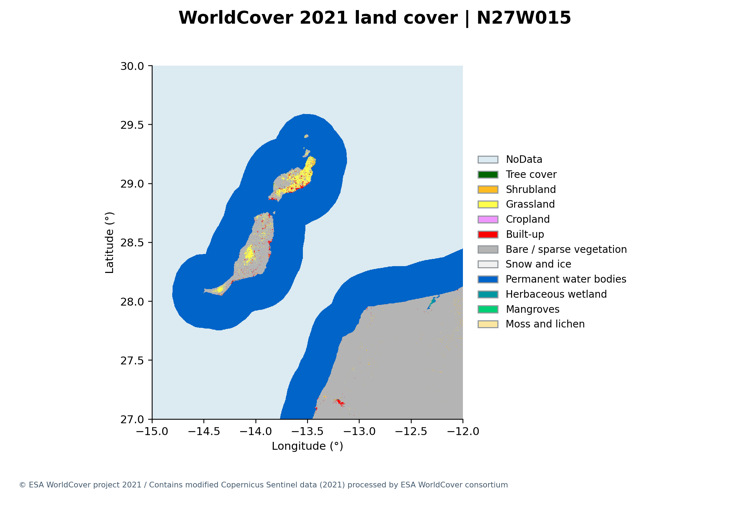

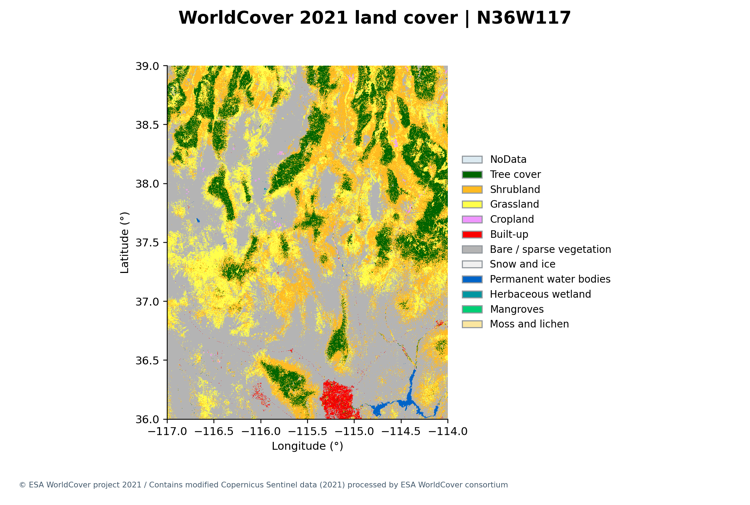

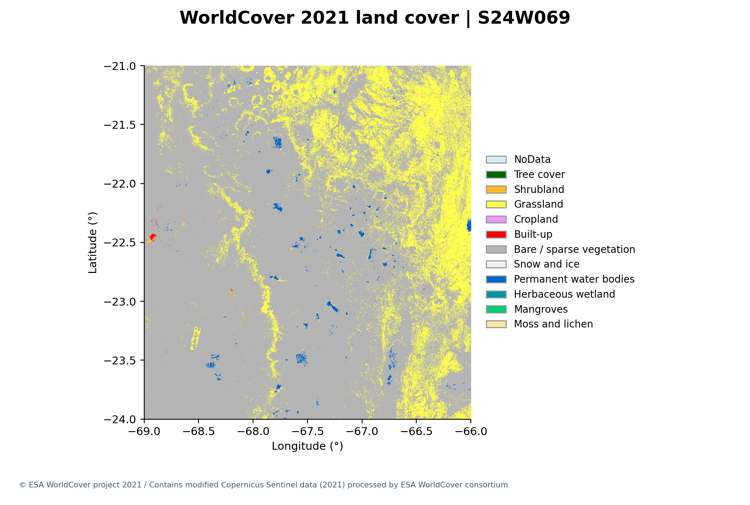

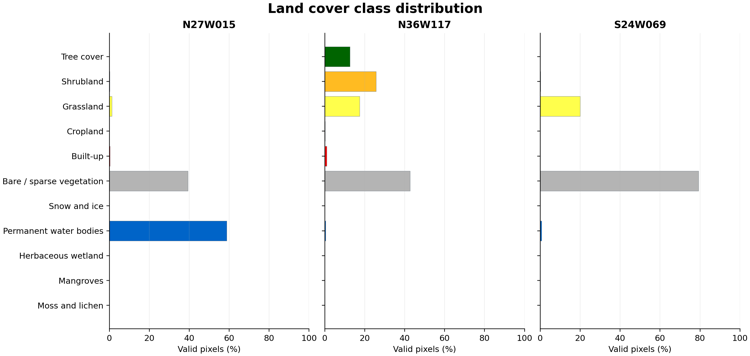

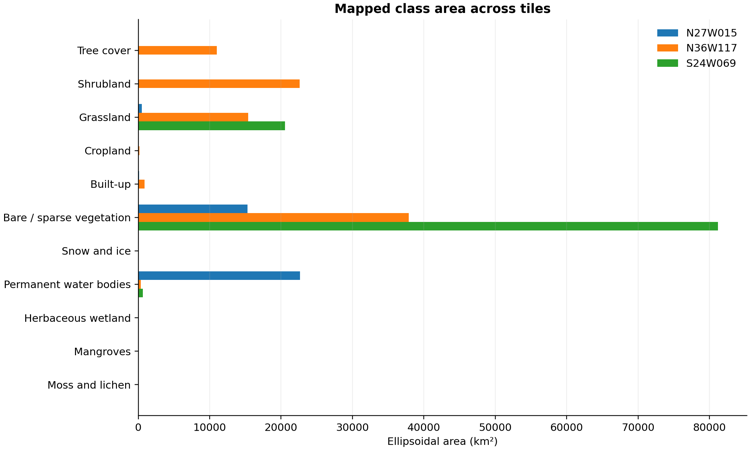

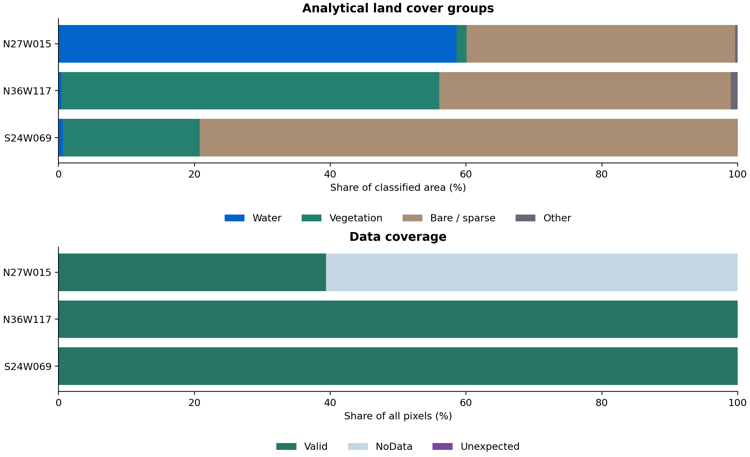

In [8]:
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.titleweight":"bold","font.size":10})
figure_paths = []
def save(fig,name):
    path = figures/f"{name}.png"
    fig.savefig(path,dpi=220,facecolor="white")
    plt.close(fig)
    figure_paths.append(path)

colors = ["#dceaf1",*[classes[c][1] for c in codes],"#80459e"]
labels = [classes[c][0] for c in codes]
cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(len(colors)+1)-.5,len(colors))
legend = [Patch(facecolor=color,edgecolor="#93999e",label=label) for color,label in
          zip(colors,["NoData",*labels,"Unexpected"])]
if not any(q["unexpected_pixels"] for q in quality.values()):
    legend.pop()
credit = "© ESA WorldCover project 2021 / Contains modified Copernicus Sentinel data (2021) processed by ESA WorldCover consortium"
for tile,info in tiles.items():
    w,s,e,n = info["bounds_wsen"]
    dx,dy = info["resolution_deg"]
    _,sample = scan_data[tile]
    left = w+(1-stride)*dx/2
    top = n-(1-stride)*dy/2
    fig,ax = plt.subplots(figsize=(9.5,6.4))
    fig.subplots_adjust(left=.12,right=.70,bottom=.17,top=.87)
    ax.imshow(lookup[sample],cmap=cmap,norm=norm,interpolation="nearest",
              extent=(left,left+sample.shape[1]*stride*dx,top-sample.shape[0]*stride*dy,top),
              aspect=1/math.cos(math.radians((s+n)/2)))
    ax.set(xlim=(w,e),ylim=(s,n),xlabel="Longitude (°)",ylabel="Latitude (°)")
    ax.legend(handles=legend,loc="center left",bbox_to_anchor=(1.02,.5),frameon=False,fontsize=9)
    fig.suptitle(f"WorldCover 2021 land cover | {tile}",fontsize=16,fontweight="bold")
    fig.text(.025,.035,credit,fontsize=7,color="#43596c")
    save(fig,f"land_cover_{tile}")

tile_ids = list(tiles)
positions = np.arange(len(codes))
fig,axes = plt.subplots(1,len(tile_ids),sharey=True,squeeze=False,
                        figsize=(5+2.55*len(tile_ids),6),layout="constrained")
for tile,ax in zip(tile_ids,axes[0]):
    values = [r["valid_pixel_pct"] or 0 for r in class_rows if r["tile"]==tile]
    ax.barh(positions,values,color=colors[1:-1],edgecolor="#77828b",linewidth=.35)
    ax.set(title=tile,xlabel="Valid pixels (%)",xlim=(0,100),yticks=positions,yticklabels=labels)
    ax.grid(axis="x",alpha=.2)
axes[0,0].invert_yaxis()
fig.suptitle("Land cover class distribution",fontsize=16,fontweight="bold")
save(fig,"class_distribution")

fig,ax = plt.subplots(figsize=(10,6),layout="constrained")
width = .78/len(tile_ids)
for i,tile in enumerate(tile_ids):
    values = [r["area_km2"] for r in class_rows if r["tile"]==tile]
    ax.barh(positions+(i-(len(tile_ids)-1)/2)*width,values,width,label=tile)
ax.set(title="Mapped class area across tiles",xlabel="Ellipsoidal area (km²)",yticks=positions,yticklabels=labels)
ax.invert_yaxis()
ax.legend(frameon=False)
ax.grid(axis="x",alpha=.2)
save(fig,"class_area_comparison")

fig,axes = plt.subplots(2,1,figsize=(10.5,6.4),layout="constrained")
panels = [
    ("Analytical land cover groups","Share of classified area (%)",[
        (group,color,[r["valid_area_pct"] or 0 for r in group_rows if r["group"]==group])
        for group,color in zip(groups,["#0064c8","#258070","#a98d74","#6d667b"])]),
    ("Data coverage","Share of all pixels (%)",[
        (label,color,[quality[t][key] for t in tiles])
        for key,label,color in zip(("valid_pct","nodata_pct","unexpected_pct"),
                                   ("Valid","NoData","Unexpected"),("#267566","#c4d7e3","#7946a0"))]),
]
for ax,(title,xlabel,series) in zip(axes,panels):
    base = np.zeros(len(tile_ids))
    for label,color,values in series:
        ax.barh(tile_ids,values,left=base,color=color,label=label)
        base += np.asarray(values)
    ax.set(title=title,xlabel=xlabel,xlim=(0,100))
    ax.invert_yaxis()
    ax.legend(loc="upper center",bbox_to_anchor=(.5,-.29),ncol=4,frameon=False)
save(fig,"groups_and_data_quality")

from io import BytesIO
for path in figure_paths:
    with Image.open(path) as image:
        image.thumbnail((750,580))
        buffer = BytesIO()
        image.save(buffer,format="PNG")
        display(NotebookImage(data=buffer.getvalue()))
for tile,q in quality.items():
    if q["dominant_class"]:
        print(f"{tile}: {q['dominant_class']} covers {q['dominant_pct_area']:.2f}% of classified area.")

## 9. NASADEM Compatibility Assessment

Compare geographic bounds and the proportion of classified WorldCover pixels inside each NASADEM footprint. NASADEM borders are defined by the outer elevation posts. The grids use different spacings and registrations.

In [9]:
print(f"NASADEM tiles available: {len(dem)}. Pairings checked: {len(pairs)}.")
for p in pairs:
    if "window" in p:
        pct = p["worldcover_valid_pct"]
        p["classified_coverage"] = "Complete" if not p["nodata_pixels"] and not p["unexpected_pixels"] else (
            "Partial" if p["valid_pixels"] else "None")
        print(f"{p['tile']} → {p['nasadem_tile']}: {p['status']}; {pct:.5f}% classified inside the intersection.")
print("WorldCover uses 0.3″ area cells. NASADEM uses 1″ elevation posts. Grid alignment requires a separate decision.")

NASADEM tiles available: 4. Pairings checked: 12.
N27W015 → n28w014: Full DEM footprint; 56.19760% classified inside the intersection.
N27W015 → n29w014: Full DEM footprint; 40.89181% classified inside the intersection.
N36W117 → n36w117: Full DEM footprint; 100.00000% classified inside the intersection.
S24W069 → s23w069: Full DEM footprint; 100.00000% classified inside the intersection.
WorldCover uses 0.3″ area cells. NASADEM uses 1″ elevation posts. Grid alignment requires a separate decision.


## 10. Results & Final Report

Verify the output images and rehash the inputs. Export class counts, areas, overlap coverage, and the reasons for each processing decision.

In [10]:
def write_csv(path,rows):
    fields = list(dict.fromkeys(key for row in rows for key in row)) or ["tile","nasadem_tile","status"]
    with path.open("w",encoding="utf-8",newline="") as stream:
        writer = csv.DictWriter(stream,fieldnames=fields)
        writer.writeheader()
        for row in rows:
            writer.writerow({k:json.dumps(v) if isinstance(v,(list,dict)) else v for k,v in row.items()})

def write_json(path,value):
    path.write_text(json.dumps(value,indent=2,ensure_ascii=False,allow_nan=False),encoding="utf-8")

source_hashes = {info["path"]:checksum(path)==info["sha256"] for path,info in inspected.items()}
assert all(source_hashes.values())
assert len(quality)==len(tiles) and len(figure_paths)==len(tiles)+3
for path in figure_paths:
    with Image.open(path) as png:
        assert png.width>=1600 and png.height>=1000
        png.verify()
write_csv(reports/"per_tile_statistics.csv",list(quality.values()))
write_csv(reports/"class_comparison.csv",class_rows)
write_csv(reports/"land_cover_groups.csv",group_rows)
write_csv(reports/"nasadem_compatibility.csv",pairs)
write_json(metadata/"raster_metadata.json",dict(
    product="ESA WorldCover 2021 v200 Map",sources=[{k:v for k,v in info.items() if k not in ("offsets","lengths")}
                                                     for info in inspected.values()],
    classes=classes,references=[manual,doi],nasadem_geometry=dem,
    source_hashes_unchanged=source_hashes))
write_json(metadata/"processing_audit.json",dict(
    decisions=audit,group_code_mapping=groups,derived_rasters=[],
    counts="Exact native-resolution block scan with tile-level atomic checkpoints.",
    area="WGS 84 ellipsoid integral between pixel edges, weighted by exact row counts, in square kilometers.",
    display=f"Class samples every {stride}th native row and column.",
    denominators=dict(quality="All pixels",class_percent="Valid pixels",area_percent="Classified ellipsoidal area"),
    verification=["All inputs passed SHA-256 comparison","Class totals match valid pixel counts",
                  "Class percentages sum to 100% on valid coverage","Row areas close to footprint area",
                  "All figure files pass integrity and resolution checks"]))

lines = ["# ESA WorldCover 2021 v200 quality report","",
         f"Inspected {len(inspected)} GeoTIFFs in {source.name}. Analyzed {len(tiles)} Map tiles. "
         "All original TIFF SHA-256 hashes matched before and after processing.","",
         "| Tile | Valid pixels | Valid % | NoData % | Unexpected | Distinct classes | Classified km² | Dominant by area |",
         "|---|---:|---:|---:|---:|---:|---:|---|"]
for tile,q in quality.items():
    dominant = f"{q['dominant_class']} ({q['dominant_pct_area']:.2f}%)" if q["dominant_class"] else "None"
    lines.append(f"| {tile} | {q['valid_pixels']:,} | {q['valid_pct']:.5f} | {q['nodata_pct']:.5f} | "
                 f"{q['unexpected_pixels']:,} | {q['distinct_classes']} | {q['valid_area_km2']:,.2f} | {dominant} |")
summary = lines.copy()
lines += ["","## Distribution and cleaning",""]
for tile in tiles:
    leaders = sorted([r for r in class_rows if r["tile"]==tile and r["pixel_count"]],
                     key=lambda r:r["area_km2"],reverse=True)[:3]
    description = ", ".join(f"{r['class_name']} {r['valid_area_pct']:.2f}%" for r in leaders)
    lines.append(f"- {tile}: {description or 'No classified area'}.")
action = ("No cleaning was required. Every classified pixel had an official code."
          if all(not q["unexpected_pixels"] for q in quality.values())
          else "Unexpected codes were recorded for investigation and excluded from classified statistics.")
lines += ["",action+" Code 0 is declared NoData. Class 80 is permanent water and is included in valid totals. "
          "Source codes, CRS, spatial resolution, and registration were preserved.","","## NASADEM compatibility",""]
for p in pairs:
    if "window" in p:
        lines.append(f"- {p['tile']} → {p['nasadem_tile']}: {p['dem_footprint_pct']:.2f}% geometric "
                     f"footprint overlap and {p['worldcover_valid_pct']:.5f}% classified coverage in that footprint.")
if not dem:
    lines.append("NASADEM metadata was unavailable.")
lines += ["","Both datasets use EPSG:4326 in the intersecting grids. WorldCover has 0.3″ area cells and "
          "NASADEM has 1″ points. Use separate grids until a target alignment is chosen.","",
          "## Interpretation and limitations","",
          "Figures show broad spatial patterns. Fixed-stride display samples can miss small patches. "
          "Area represents the ellipsoid surface rather than slope-adjusted terrain surface. "
          "The structural checks verify codes and coverage. Independent reference observations are required to validate local map accuracy.","",
          f"[ESA Product User Manual]({manual}) · [WorldCover 2021 v200 citation]({doi})","",credit]
(reports/"dataset_quality_report.md").write_text("\n".join(lines)+"\n",encoding="utf-8")
display(Markdown("\n".join(summary)))
print(f"Verified {len(tiles)} analyzed tiles and {len(figure_paths)} high-resolution figures.")
print(output)

Verified 3 analyzed tiles and 6 high-resolution figures.
C:\Users\User\OneDrive\Documents\Desktop\NASA\ESA_WorldCover_Processed


# ESA WorldCover 2021 v200 quality report

Inspected 3 GeoTIFFs in new_data. Analyzed 3 Map tiles. All original TIFF SHA-256 hashes matched before and after processing.

| Tile | Valid pixels | Valid % | NoData % | Unexpected | Distinct classes | Classified km² | Dominant by area |
|---|---:|---:|---:|---:|---:|---:|---|
| N27W015 | 510,638,102 | 39.40109 | 60.59891 | 0 | 8 | 38,626.28 | Permanent water bodies (58.61%) |
| N36W117 | 1,296,000,000 | 100.00000 | 0.00000 | 0 | 10 | 88,316.48 | Bare / sparse vegetation (42.92%) |
| S24W069 | 1,296,000,000 | 100.00000 | 0.00000 | 0 | 9 | 102,538.29 | Bare / sparse vegetation (79.18%) |